In [13]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/Users/Simon/GIT/GPlatesClassStruggle/')
from reconstruction_classes import *

from ptt.subduction_convergence import find_overriding_and_subducting_plates

polyline = pygplates.PolylineOnSphere([(-60,40),(-50,40),(-40,35), (-20,40)])





0.000304617419787 (35.0, 40.0) 0.174532925199
0.000614256449619 (39.43198847093019, 25.76135215596254) 0.185012193521
0.00119787602312 (50.019505693616495, 40.03384971631634) 0.356988682564


[-180, 180, -90, 90]

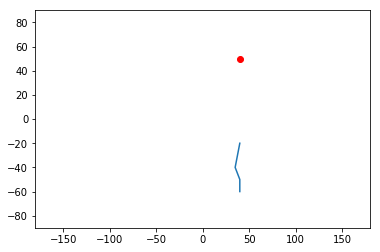

In [5]:
# cross product of normal and position of mid point

for i,segment in enumerate(polyline.get_segments()):
    
    
    normal = segment.get_great_circle_normal()
    
    segment_position_vector = segment.get_arc_point(0.5).to_xyz()
    
    segment_weight = segment.get_arc_length()
        
    stage_pole_position = pygplates.Vector3D.cross(normal,segment_position_vector)
    rotation_rate_vector = pygplates.Vector3D(stage_pole_position.to_xyz()) * np.radians(0.1)
    
    v = pygplates.Vector3D.cross(rotation_rate_vector, segment_position_vector)
    
    if i==0:
        weighting_factor = 0
        net_torque = pygplates.Vector3D(0, 0, 0)

    net_torque = net_torque + pygplates.Vector3D.cross(segment_position_vector, v) * segment_weight
    
    print net_torque.get_magnitude(), pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon(), segment_weight
    
plt.plot(polyline.to_lat_lon_array()[:,1],polyline.to_lat_lon_array()[:,0])
plt.plot(pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[1],
         pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[0],'ro')
plt.axis([-180,180,-90,90])


In [8]:
M2016 = ReconstructionModel('Matthews++2016')
M2016.add_rotation_model('/Users/simon/GIT/agegrid-dev/input_files/Rotations/Matthews_etal_GPC_2016_410-0Ma_GK07.rot')
M2016.add_static_polygons('/Users/simon/GIT/agegrid-dev/input_files/StaticPolygons/Muller_etal_AREPS_2016_StaticPolygons.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_MesozoicCenozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_Paleozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_TopologyBuildingBlocks.gpml')



skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
skipping segment without exactly 2 shared polygons
0.00273700462281


[-180, 180, -90, 90]

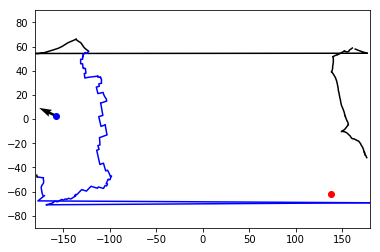

In [132]:
def get_torque_for_segment(segment, subducting_normal_reversal):
    
    normal = -subducting_normal_reversal * segment.get_great_circle_normal()
    
    segment_position_vector = segment.get_arc_point(0.5).to_xyz()
    
    segment_weight = segment.get_arc_length()
    #print segment_weight
        
    stage_pole_position = pygplates.Vector3D.cross(normal,segment_position_vector)
    rotation_rate_vector = pygplates.Vector3D(stage_pole_position.to_xyz()) * np.radians(0.1)
    
    v = pygplates.Vector3D.cross(rotation_rate_vector, segment_position_vector)

    segment_torque = pygplates.Vector3D.cross(segment_position_vector, v) * segment_weight

    return segment_torque


reconstruction_time = 35.
target_plate_id = 901

snapshot = M2016.plate_snapshot(reconstruction_time)

net_torque = pygplates.Vector3D(0, 0, 0)


forces = ['slab_pull','slap_suction']
#forces = ['slab_pull']


for topology in snapshot.resolved_topological_sections:
    
    shared_sub_segments = topology.get_shared_sub_segments()
    for shared_sub_segment in shared_sub_segments:
        
        # if the segment is not topologically correct, skip it
        if len(shared_sub_segment.get_sharing_resolved_topologies()) != 2:
            print 'skipping segment without exactly 2 shared polygons'
            continue
        
        # check if the segment is part of the boundary of the target plate
        if target_plate_id in [resolved_topology.get_feature().get_reconstruction_plate_id() for resolved_topology in shared_sub_segment.get_sharing_resolved_topologies()]:            
            
            # check if it is a subduction zone
            if shared_sub_segment.get_resolved_feature().get_feature_type() == pygplates.FeatureType.gpml_subduction_zone:
                
                # find which of the plate pair is the overriding plate, and identify polarity
                (overriding_plate, 
                 subducting_plate, 
                 subduction_polarity) = find_overriding_and_subducting_plates(shared_sub_segment, reconstruction_time)
                            
                
                if subducting_plate.get_resolved_feature().get_reconstruction_plate_id() == target_plate_id:
                    
                    if 'slab_pull' in forces:
                    
                        if subduction_polarity == 'Left':
                            subducting_normal_reversal = 1
                        else:
                            subducting_normal_reversal = -1

                        for segment in shared_sub_segment.get_resolved_feature().get_geometry().get_segments():
                            segment_torque = get_torque_for_segment(segment, subducting_normal_reversal)

                            net_torque = net_torque + segment_torque

                    plt.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                             shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],'k')
                
                if overriding_plate.get_resolved_feature().get_reconstruction_plate_id() == target_plate_id:
                    
                    if 'slap_suction' in forces:
                        
                        if subduction_polarity == 'Left':
                            subducting_normal_reversal = -1
                        else:
                            subducting_normal_reversal = 1

                        for segment in shared_sub_segment.get_resolved_feature().get_geometry().get_segments():
                            segment_torque = get_torque_for_segment(segment, subducting_normal_reversal)

                            net_torque = net_torque + segment_torque * 0.5
                        
                    plt.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                             shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],'r')
                
                
            elif shared_sub_segment.get_resolved_feature().get_geometry() is not None:
                plt.plot(shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,1],
                         shared_sub_segment.get_resolved_feature().get_geometry().to_lat_lon_array()[:,0],'b')


#print net_torque
print net_torque.get_magnitude()
#print pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()               

equivalent_stage_rotation = pygplates.FiniteRotation(pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon(),
                                                     net_torque.get_magnitude())

for topology in snapshot.resolved_topologies:
    if topology.get_resolved_feature().get_reconstruction_plate_id() == target_plate_id:
        centroid_point = topology.get_resolved_geometry().get_interior_centroid()

delta_time = 10.
velocity_vectors = pygplates.calculate_velocities(
                        [centroid_point],
                        equivalent_stage_rotation,
                        delta_time)

# Convert global 3D velocity vectors to local (magnitude, azimuth, inclination) tuples (one tuple per point).
velocity_ne = pygplates.LocalCartesian.convert_from_geocentric_to_north_east_down(
    [centroid_point],
    velocity_vectors)[0]


plt.plot(pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[1],
         pygplates.PointOnSphere(net_torque.to_normalised().to_xyz()).to_lat_lon()[0],'ro')

plt.plot(centroid_point.to_lat_lon()[1],
         centroid_point.to_lat_lon()[0],'bo')

plt.quiver(centroid_point.to_lat_lon()[1],
           centroid_point.to_lat_lon()[0],
           velocity_ne.get_y(),
           velocity_ne.get_x(),units='xy')

plt.axis([-180,180,-90,90])
